In [1]:
# Initialize Otter
import otter
grader = otter.Notebook("hwk2-task2-salmon.ipynb")

# Task 2: Wrangling Alaska salmon catch data 

## Instructions 

- First, update the following cell to have a link to *your* Homework 2 GitHub repository:

**UPDATE THIS LINK**
https://github.com/veronica-moran/eds220-hwk2.git


- Review the [complete rubric for this task](https://docs.google.com/document/d/1x0BoU6IH4cnOR1-n7i9CYQ9wUC37yDpYlQ4j6rCfcsU/edit?tab=t.0) before starting.

- **Meaningful commits should be made every time you finish a major step.** We'll check your repository and view the commit history.

- **Every code cell should have a comment.** Err on the side of commenting too much for now. Comments should follow best practices.

- **Do not update the top cell with the `otter` import**, this is used internally for grading.

## Acknowledgments

This exercise is based on the [Cleaning and Wrangling Data in R lesson by the NCEAS Learning Hub](https://learning.nceas.ucsb.edu/2023-06-delta/session_11.html).


> Halina Do-Linh, Carmen Galaz García, Matthew B. Jones, Camila Vargas Poulsen. 2023. Open Science Synthesis training Week 1. NCEAS Learning Hub & Delta Stewardship Council.


## About the data

In this task you will use simplified data from the Alaska Department of Fish & Game containing commercial salmon catch data from 1878 to 1997. The original data can be accessed from the KNB repository:

> [Mike Byerly. (2016). Alaska commercial salmon catches by management region (1886-1997).](https://knb.ecoinformatics.org/view/df35b.304.2) Gulf of Alaska Data Portal. df35b.304.2.

The simplified dataset is in CSV format in the homework repository and has the following columns:

| Column | Description |
| ------ | ----------- | 
| Region | Region code |
| Year | Year fish were caught |
| notesRegCode | Notes and comments |
| Species | Species of salmon caught |
| Catch | Commercial catches of salmon species (in thousands of fish) |

## COMPLETE WORKFLOW

You will use the next code cell to complete the last exercise in the task. Leave it blank for now. 

In [2]:
# FINAL CODE
import pandas as pd

catch_data = pd.read_csv("data/salmon_data.csv")

catch_data = catch_data.drop(columns = 'notesRegCode')

catch_data.loc[catch_data['Catch'].str.contains('I')]

catch_data.at[400,'Catch'] = 1

catch_data['Catch'] = catch_data['Catch'].astype('int64')

avg_region = catch_data.groupby('Region')['Catch'].mean()

avg_region.sort_values().plot(kind = 'barh',
               title = 'Average Estimated Salmon Catches by Region (1878 -1997)',
                              xlabel = 'Average Catches',
                              ylabel = 'Region')


<Axes: title={'center': 'Average Estimated Salmon Catches by Region (1878 -1997)'}, xlabel='Average Catches', ylabel='Region'>

## 1

a. Use this code cell to import the data from the `salmon_data.csv` as `catch_data`. Look at the head of the data frame. 

<!-- BEGIN QUESTION -->



,Region,Year,notesRegCode,Species,Catch
0,SSE,1886,NaN,Chinook,0
1,SSE,1887,NaN,Chinook,0
2,SSE,1888,NaN,Chinook,0
3,SSE,1889,NaN,Chinook,0
4,SSE,1890,NaN,Chinook,0


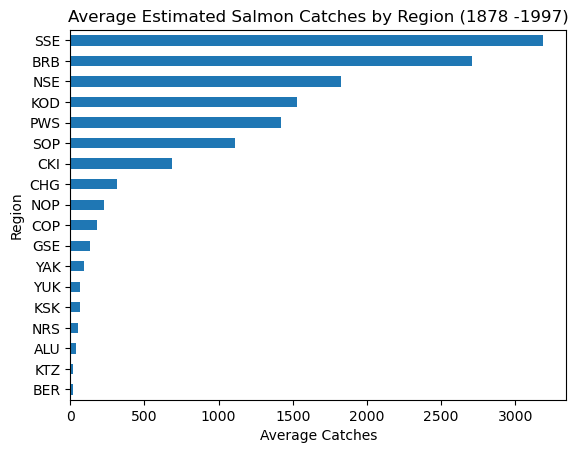

In [3]:
# a.
import pandas as pd

catch_data = pd.read_csv("data/salmon_data.csv")

catch_data.head()


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Use this code cell to make some other preliminary data exploration of your choosing.

In [4]:
# b.
print(catch_data.tail()) # Last 5 rows of data set
print(catch_data.shape) # Data set dimensions
catch_data.info() # Returns column names, non-null count, and dtype
catch_data.nunique() # Number of unique variables in a column
catch_data.isna().sum()


     Region  Year notesRegCode Species Catch
8535    NOP  1993          NaN    Chum   135
8536    NOP  1994          NaN    Chum    84
8537    NOP  1995          NaN    Chum    99
8538    NOP  1996          NaN    Chum    68
8539    NOP  1997          NaN    Chum    97
(8540, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8540 entries, 0 to 8539
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Region        8540 non-null   object
 1   Year          8540 non-null   int64 
 2   notesRegCode  1415 non-null   object
 3   Species       8540 non-null   object
 4   Catch         8540 non-null   object
dtypes: int64(1), object(4)
memory usage: 333.7+ KB


Region             0
Year               0
notesRegCode    7125
Species            0
Catch              0
dtype: int64

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

c. Use this markdown cell to explain why you decided to do the exploration in b. and what information you obtained from doing it.

I chose these four additional data exploration functions because they provide key information about the data including, column names, number of non-null values in each column, column dtypes, and summ of NA values in each column.

<!-- END QUESTION -->

## 2
In the next cell:

a. Store the unique values of the `notesRegCode` column in the `notes_unique` variable. 

In [5]:
# .unique() returns all the unique values in the 'notesRegCode' column
notes_unique = catch_data['notesRegCode'].unique() #storing unique values to variable
print(notes_unique)

[nan 'Includes Yakutat catches' 'Yakutat catch included in No SE AK catch'
 'Estimated from canned production, probably sockeye' 'No fishery'
 'Bering River catches included in Copper River catches'
 'Includes Bering River catches; estimated from canned'
 'Includes Bering River catches'
 'Coho and pink catch estimated from canned production'
 'Includes Bering River; coho and pink estimated fro canned'
 'Pink catch estimated from canned'
 'Includes Bering River; coho pink and chum estimated from canned'
 'Includes Bering River; pink estimated from canned'
 'Includes Bering River; pink and chum estimated from canned'
 'Includes Copper River catches'
 'Includes Copper River catches; coho catch porbably mostly pinks'
 'Eshamy District only' 'Estimated from canned; excludes Resurrection Bay'
 'Estimated from canned production' 'No Resurrection Bay fishery'
 'Resurrection bay contribution estimated from canned production'
 'No reported catch'
 'Sockeye and pink and 9922 chum from Port Claren

In [6]:
grader.check("q2a")

q2a results: All test cases passed!

b. Update the data frame so it doesn't include the `notesRegCode` column. Verify the column is no longer in the data frame.

In [7]:
# Dropping the 'notesRegCode' column, and updating original data frame
catch_data = catch_data.drop(columns = 'notesRegCode')

In [8]:
# Veryfying 'notesRegCode' column was dropped
catch_data.columns

Index(['Region', 'Year', 'Species', 'Catch'], dtype='object')

In [9]:
grader.check("q2b")

q2b results: All test cases passed!

<!-- BEGIN QUESTION -->

## 3
Does each column have the expected data type? Use this code cell to obtain this information and write your answer in the next markdown cell.


Each column except `Catch` has the data type I expected. The `Catch` column should be int64

In [10]:
# Output prints dtypes for each column
catch_data.dtypes

Region     object
Year        int64
Species    object
Catch      object
dtype: object

<!-- END QUESTION -->

## 4 
The following cell shows a first attempt at updating the `Catch` column to be of data type `int64` instead of `object`. Converting from one data type to another is often called **casting**. 

To do it we use the [`astype()`](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.Series.astype.html) method for `pandas.Series`. The `astype()` method does not modify the `pandas.Series` in place.

Run the next cell and read the end of the error message closely.

In [11]:
catch_data['Catch'].astype('int64')

ValueError: invalid literal for int() with base 10: 'I'

## 5 

The previous error tells us there is a value 'I' (as in the letter 'I') that could not be converted to integer type. It turns out the original data set was created from a PDF which was automatically converted into a CSV file and this 'I' value should be 1.

In the next cell find the row(s) causing this issue. Show the filtered row(s) as the output. Store your answer in the `catch_I` variable. `catch_I` should have one observation and contain the following columns: Region, Year, Species, Catch. It should contain the original index number in order to pass the test. 

In [ ]:
# Locating row where the 'Catch' column has a value that cointains 'I', and storing to a variable
catch_I = catch_data.loc[catch_data['Catch'].str.contains('I')]
catch_I 

In [ ]:
grader.check("q5")

## 6
In the next cell:

1. Update the value of I to 1.
2. Access the row you updated to verify the value was changed and store this single row in the `catch_1` variable. 

<!-- BEGIN QUESTION -->



In [ ]:
# Updating the value of the cell at row 400 column 'Catch' to 1, saving to a variable

catch_1 = catch_data.at[400,'Catch'] = 1

# Print catch_1
catch_1

<!-- END QUESTION -->

## 7
In the next cell:

1. Update the `Catch` column in `catch_data` to be of type `int64`.
2. Confirm you have updated the data type. Store the type of the `Catch` column in the `catch_column_type` variable.

In [ ]:
# Setting the type of the 'Catch' column as 'int64', updating the data frame 

catch_data['Catch'] = catch_data['Catch'].astype('int64')
catch_column_type = catch_data['Catch'].dtype # Storing the type of the 'Catch' column as a variable
catch_column_type

In [ ]:
grader.check("q7")

<!-- BEGIN QUESTION -->

## 8
Create a data frame with the average salmon catch per region. HINT: use `groupby()`. Store your data frame in a new variable called `avg_region`


In [ ]:
# Grouping by region, taking the mean of the 'Catch' values, sorting values

avg_region = catch_data.groupby('Region')['Catch'].mean().sort_values() # Storing data frame to a variable
avg_region

In [ ]:
grader.check("q8")

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

## 9 

Use the data frame you created in 8 to make a bar graph of the estimated average salmon catches by region from 1878 to 1997. The bars in the graph should be ordered by magnitude (increasing or decreasing is ok). Add a title to your graph and update the axes labels if needed (check the units for the salmon catch). 

In [ ]:
# Plotting values on a horizontal bar graph
avg_region.sort_values().plot(kind = 'barh',
               title = 'Average Estimated Salmon Catches by Region (1878 -1997)',
               xlabel = 'Average Catches (thousands of fish)',
               ylabel = 'Region')

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

## 10

Write a brief description with key takeaways from the plot. Your answer should use the complete names for the management areas instead of their codes. You can find what each code stands for in the [original data repository](https://knb.ecoinformatics.org/view/df35b.304.2#df35b.303.1).

The Alaska Department of Fish & Game data set contains commercial salmon catch data for eighteen regions from 1878  to 1997. This data exploration shows that over half of the combined regional averages were associated with three regions: Southern Southeast Alaska, Bristol Bay Management Area, and Northern Southeast Alaska. Southern Southeast Alaska region had the highest average catches, and Bering River Subarea Copper River Subarea had the lowest average catches.

<!-- END QUESTION -->

## 11

Collect all the relevant code into the first blank cell of the notebook titled "COMPLETE WORKFLOW". This single cell will have the end-to-end workflow: from importing libraries and loading the data, to producing the graph. The *only* output of this cell should be the graph you produced in the previous exercise. Further guidance on what to include in this final workflow is in the [assignment rubric](https://docs.google.com/document/d/1x0BoU6IH4cnOR1-n7i9CYQ9wUC37yDpYlQ4j6rCfcsU/edit?tab=t.0).

---

To double-check your work, the cell below will rerun all of the autograder tests.

In [ ]:
grader.check_all()